# 01 EDA: data screening for the Hallsta energy MFA (reference year 2023)
Purpose: show what the source register (`data/sources.csv`) says, where vintages disagree, and which values the model uses. All numbers are read by id from the register; derived quantities are labelled *derived*. Figures go to `reports/figures/eda_*.png`, data behind them to `reports/tables/eda_*.csv`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Markdown, display
from hallsta_mfa import plotstyle
plotstyle.use()
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TAB = ROOT / 'reports' / 'tables'; TAB.mkdir(parents=True, exist_ok=True)
src = pd.read_csv(ROOT / 'data' / 'sources.csv').set_index('id')
def v(i): return float(src.loc[i, 'value'])
def rng(i): return float(src.loc[i, 'value_low']), float(src.loc[i, 'value_high'])
def tab(df, name): df.to_csv(TAB / f'eda_{name}.csv', index=False); return df
def say(s): display(Markdown(s))
C = plotstyle.CARRIER; S = plotstyle.SERIES; INK, INK2, INK3 = plotstyle.INK, plotstyle.INK_2, plotstyle.INK_3
YRS = [2019, 2020, 2021, 2022, 2023]
# Model values supplied for the reconciliation (not in the register)
MODEL = dict(E_GWh=1450, shares=(70, 15, 10, 5), tmp_steam_th=100, pm_steam_th=95, pm_steam_rng=(80, 110),
             boiler_eff=0.98, boiler_yield=1.5, p_bar_abs=3.4, T_steam=138, T_cond=90, h_steam_GJt=2.35,
             T_eff=35, eff_Mm3=7.289, hours=7200, dh_GWh=11.877)
def nq(i): return f"“{src.loc[i,'quote']}”"
H = MODEL['h_steam_GJt']; HRS = MODEL['hours']; P23 = v('prod_paper_2023')

## 1. Five-year context, 2019-2023 (Miljörapport Tabell 13)
Electricity, diesel and specific energy consumption (SEC, MWh per F-ton paper) are reported; annual production is not in Tabell 13, so it is *derived* as electricity / SEC. For 2023 Tabell 3 also reports production directly.

**Supports report §3.4 (and §5.2):** 2023 is a usable reference year; its low output and stops (price, market, MBBR) raise SEC, but Holmen also reports higher SEC in full-run periods, so the SEC is not only a stop effect.

*Caption:* Electricity, derived paper production and specific energy consumption at Hallsta, 2019-2023 (Miljörapport Tabell 13). 2023 (shaded) is the second-lowest output year and has the highest SEC; Miljörapport §1.2.1 attributes this to price- and market-driven stops and the MBBR outage, and also to a higher SEC in full-run periods.

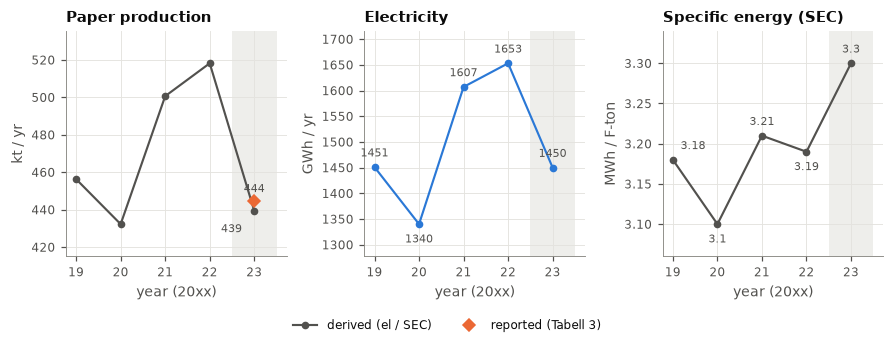

**Takeaway.** 2023 derived output (439 kt; Tabell 3 reports 444 kt) ranks 2 of 5 from the bottom, and SEC (3.3 MWh/t) is the highest of the five years, so 2023 is a low-output, high-intensity year rather than a typical one. Electricity is lower than 2021-22 but the SEC rises because output fell more. Diesel is 2.7-3.2 GWh/yr (below 0.3 % of electricity) and is negligible. Miljörapport §1.2.1 attributes part of this to stops, citing planned stops due to electricity price (`narr_price_stops_2023`: “Planerade stopp på grund av elpris bidrar till en ökad förbrukning av el per ton papper.”, 'planned stops because of electricity price add to electricity per tonne') and months with much stop time from MBBR absence and market causes (`narr_market_stops_2023`: “vissa månader präglats av en hel del stopptid, både på grund av helt eller delvis avsaknad från MBBR:enliksom av marknadsrelaterade orsaker.”, 'partly or fully without the MBBR and for market-related reasons'; MBBR fully stopped 81 days, `mbbr_stop_days_2023`). It also says the SEC in full-production periods has risen versus history (`narr_full_run_sec_2023`: “Den specifika elförbrukningen under perioder då produktionen har gått fullt har tyvärr ökat i föhållande till historiska värden.”, 'unfortunately increased relative to historical values'), so the high 2023 SEC is not only a stop effect.

In [2]:
t13 = pd.DataFrame({'year': YRS,
    'electricity_GWh': [v(f'el_total_{y}_t13') for y in YRS],
    'diesel_GWh': [v(f'diesel_gwh_{y}_t13') for y in YRS],
    'sec_MWh_per_t': [v(f'spec_energy_{y}_t13') for y in YRS]})
t13['production_derived_kt'] = t13.electricity_GWh / t13.sec_MWh_per_t
t13['production_reported_kt'] = [np.nan]*4 + [v('prod_paper_2023')/1e3]
tab(t13, 'context_2019_2023')
fig, ax = plt.subplots(1, 3, figsize=(8.2, 2.9))
a = ax[0]; a.plot(t13.year, t13.production_derived_kt, '-o', color=INK2, ms=4, lw=1.4, label='derived (el / SEC)')
a.plot([2023], [v('prod_paper_2023')/1e3], 'D', color=S[1], ms=6, label='reported (Tabell 3)')
a.set_title('Paper production'); a.set_ylabel('kt / yr'); 
a.annotate(f"{t13.production_derived_kt.iloc[-1]:.0f}", (2023, t13.production_derived_kt.iloc[-1]), xytext=(-8, -14), textcoords='offset points', ha='right', fontsize=7, color=INK2)
a.annotate(f"{v('prod_paper_2023')/1e3:.0f}", (2023, v('prod_paper_2023')/1e3), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=7, color=INK2)
a = ax[1]; a.plot(t13.year, t13.electricity_GWh, '-o', color=C['electricity'], ms=4, lw=1.4)
a.set_title('Electricity'); a.set_ylabel('GWh / yr')
a = ax[2]; a.plot(t13.year, t13.sec_MWh_per_t, '-o', color=INK2, ms=4, lw=1.4)
a.set_title('Specific energy (SEC)'); a.set_ylabel('MWh / F-ton')
for a, col in zip(ax[1:], ['electricity_GWh', 'sec_MWh_per_t']):
    for y, val in zip(t13.year, t13[col]):
        dn = y == 2020 or (col == 'sec_MWh_per_t' and y == 2022)
        right = col == 'sec_MWh_per_t' and y == 2019
        a.annotate(f"{val:g}", (y, val), xytext=(5 if right else 0, -12 if dn else 7), textcoords='offset points', ha='left' if right else 'center', fontsize=7, color=INK2)
for a in ax:
    a.set_xticks(YRS); a.set_xticklabels([str(y)[2:] for y in YRS]); a.set_xlabel('year (20xx)')
    a.axvspan(2022.5, 2023.5, color=plotstyle.GRID, alpha=.6, lw=0)
    a.margins(y=.2)
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, ncol=2, loc='upper center', bbox_to_anchor=(.5, 0.02), frameon=False)
fig.tight_layout(); plotstyle.save(fig, 'eda_context'); plt.show()
rk = t13.production_derived_kt.rank().iloc[-1]
mb = src.loc['mbbr_stop_days_2023']
say(f"**Takeaway.** 2023 derived output ({t13.production_derived_kt.iloc[-1]:.0f} kt; Tabell 3 reports {v('prod_paper_2023')/1e3:.0f} kt) ranks {int(rk)} of 5 from the bottom, and SEC ({t13.sec_MWh_per_t.iloc[-1]} MWh/t) is the highest of the five years, so 2023 is a low-output, high-intensity year rather than a typical one. Electricity is lower than 2021-22 but the SEC rises because output fell more. Diesel is 2.7-3.2 GWh/yr (below 0.3 % of electricity) and is negligible. "
    f"Miljörapport §1.2.1 attributes part of this to stops, citing planned stops due to electricity price (`narr_price_stops_2023`: {nq('narr_price_stops_2023')}, 'planned stops because of electricity price add to electricity per tonne') and months with much stop time from MBBR absence and market causes (`narr_market_stops_2023`: {nq('narr_market_stops_2023')}, 'partly or fully without the MBBR and for market-related reasons'; MBBR fully stopped {mb.value:.0f} days, `mbbr_stop_days_2023`). "
    f"It also says the SEC in full-production periods has risen versus history (`narr_full_run_sec_2023`: {nq('narr_full_run_sec_2023')}, 'unfortunately increased relative to historical values'), so the high 2023 SEC is not only a stop effect.")

## 2. Electricity split across data vintages (MWh per tonne of paper)
Four vintages: (a) Holmen slide (undated) *Viktiga energiflöden* (year unknown, 565 kt/yr, per-tonne values as given); (b) 2019 answer (3-yr-average shares) applied to the 2019 total and derived 2019 production; (c) Aug 2019 monthly line values (single month: shares only); (d) 2025 answer shares applied to 2023 total and 2023 reported production. Shares for (d) sum to 95 %; the 5 % remainder is shown as unassigned.

**Supports report §4.1, §6.2 and §7:** the TMP 65-75 %, PM 12-22 % and electric-boiler 5-12 % ranges span the vintages, and boiler intensity has risen, which motivates the measures.

*Caption:* Electricity split by process in four data vintages, as MWh per tonne of paper (left) and share of total (right). The Aug 2019 line values are one month and give shares only; electric-boiler intensity rises from 0.12 to 0.33 MWh/t.

,TMP MWh/t,PM + other MWh/t,Electric boilers MWh/t,Unassigned MWh/t,TMP %,PM + other %,Electric boilers %,Unassigned %
vintage,,,,,,,,
(a) Holmen slide (undated),2.20,0.70,0.12,0.00,72.85,23.18,3.97,0.0
(b) 2019 answer (3-yr avg shares),2.29,0.70,0.19,0.00,72.00,22.00,6.00,0.0
(c) Aug 2019 line values (month),NaN,NaN,NaN,NaN,79.24,20.76,0.00,0.0
"(d) 2025 answer, applied to 2023",2.28,0.49,0.33,0.16,70.00,15.00,10.00,5.0


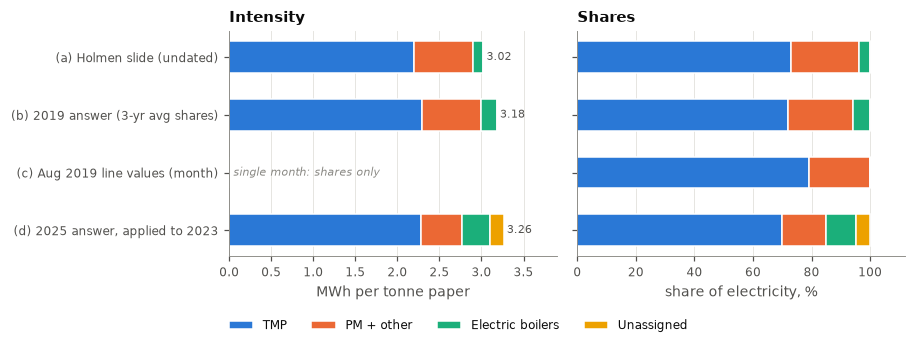

**Takeaway.** Electric-boiler intensity rises from 0.12 (Holmen slide (undated)) via 0.19 (2019 answer) to 0.33 MWh/t (2025 answer on 2023 data); TMP stays near 2.2-2.3 MWh/t, and PM falls from 0.70 to 0.49. The Aug 2019 monthly values cover no boilers and sum to 106 GWh, below the ~121 GWh/month implied by the 2019 annual total, so they only support the TMP/PM ratio. The vintages differ in year, basis and production, so the step in boiler share is indicative, not a measured trend.

In [3]:
cats = ['TMP', 'PM + other', 'Electric boilers', 'Unassigned']
tot19 = v('el_total_2019_t13'); p19 = t13.production_derived_kt.iloc[0]*1e3
tot23 = v('el_total_2023_t13'); sec19 = tot19*1e3/p19
rows = {}
rows['(a) Holmen slide (undated)'] = [v('pptx_tmp_in'), v('pptx_pm'), v('pptx_ep'), 0]
s19 = [v('el_split_tmp_2019'), v('el_split_pm_2019'), v('el_split_boiler_2019')]
rows['(b) 2019 answer (3-yr avg shares)'] = [tot19*1e3*s/100/p19 for s in s19] + [0]
s25 = [v('el_split_tmp_2025'), v('el_split_pm_2025'), v('el_split_boiler_2025')]
s25.append(100 - sum(s25))
rows['(d) 2025 answer, applied to 2023'] = [tot23*1e3*s/100/P23 for s in s25]
tmp3, tmp12, pm11, pm12 = [v(f'el_{k}_aug2019') for k in ['tmp3','tmp12','pm11','pm12']]
aug = np.array([tmp3+tmp12, pm11+pm12, 0, 0]); aug_sh = aug/aug.sum()*100
mwh = pd.DataFrame(rows, index=cats).T
shares = mwh.div(mwh.sum(axis=1), axis=0)*100
shares.loc['(c) Aug 2019 line values (month)'] = aug_sh
order = ['(a) Holmen slide (undated)', '(b) 2019 answer (3-yr avg shares)', '(c) Aug 2019 line values (month)', '(d) 2025 answer, applied to 2023']
mwh = mwh.reindex(order); shares = shares.reindex(order)
out = pd.concat([mwh.add_suffix(' MWh/t'), shares.add_suffix(' %')], axis=1).round(3).reset_index(names='vintage')
tab(out, 'electricity_split'); display(out.set_index('vintage').round(2))
fig, ax = plt.subplots(1, 2, figsize=(8.4, 2.9), sharey=True)
y = np.arange(4)[::-1]
for k, (a, df, lab) in enumerate(zip(ax, [mwh, shares], ['MWh per tonne paper', 'share of electricity, %'])):
    left = np.zeros(4)
    for j, c in enumerate(cats):
        vals = df[c].fillna(0).values
        a.barh(y, vals, left=left, height=.55, color=S[j], edgecolor='white', linewidth=1, label=c)
        left += vals
    a.set_xlabel(lab); a.set_yticks(y); a.set_yticklabels(order)
    a.grid(axis='y', visible=False)
    for yy, tt in zip(y, left):
        if tt > 0 and k == 0: a.text(tt + (0.04 if k == 0 else 1), yy, f"{tt:.2f}" if k == 0 else f"{tt:.0f}", va='center', fontsize=7, color=INK2)
ax[0].text(0.05, y[2], 'single month: shares only', va='center', fontsize=7.5, color=INK3, style='italic')
ax[0].set_xlim(0, 3.9); ax[1].set_xlim(0, 112)
ax[0].set_title('Intensity'); ax[1].set_title('Shares')
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, ncol=4, loc='upper center', bbox_to_anchor=(.5, 0.02), frameon=False)
fig.tight_layout(); plotstyle.save(fig, 'eda_electricity_split'); plt.show()
eb = mwh['Electric boilers']
say(f"**Takeaway.** Electric-boiler intensity rises from {eb.iloc[0]:.2f} (Holmen slide (undated)) via {eb.iloc[1]:.2f} (2019 answer) to {eb.iloc[3]:.2f} MWh/t (2025 answer on 2023 data); TMP stays near {mwh.TMP.iloc[0]:.1f}-{mwh.TMP.iloc[3]:.1f} MWh/t, and PM falls from {mwh['PM + other'].iloc[0]:.2f} to {mwh['PM + other'].iloc[3]:.2f}. The Aug 2019 monthly values cover no boilers and sum to {aug.sum()/1e3:.0f} GWh, below the ~{tot19/12:.0f} GWh/month implied by the 2019 annual total, so they only support the TMP/PM ratio. The vintages differ in year, basis and production, so the step in boiler share is indicative, not a measured trend.")

## 3. Steam recovered from TMP, per tonne of paper
Sources give steam on different bases (MWh/t, t/h, GJ with unstated period). All are put on MWh steam per tonne paper using a steam enthalpy of **2.35 GJ/t** (model value, 3.4 bar abs / 138 degC to 90 degC condensate). Rows with an unstated period are shown for both readings (per month x12, per year), hatched. Right panel: the same steam as a share of the TMP electricity of that vintage.

**Supports report §5.1 (steam-loop validation, model 77 % vs Holmen 70-90 %) and §7 Measure 1:** recovered steam per tonne has fallen against the older Holmen slide value, and Holmen itself names TMP and hot-water recovery shortfalls as drivers of electric-boiler use (`narr_boiler_driver_2023`).

*Caption:* Recovered TMP steam per tonne of paper (left) and relative to TMP electricity (right) for each source basis. Hatched bars use an assumed period for values with none stated (2.35 GJ/t steam). The ~10,000 GJ/month and 145,000 GJ per year readings are physically inconsistent with 100 t/h, so they cannot refer to total TMP recovered steam.

,basis,steam_MWh_per_t_paper,tmp_el_MWh_per_t_paper,period_assumed,steam_t_per_t_paper,steam_share_of_tmp_el_pct
0,Holmen slide: 1.2 MWh/t,1.200,2.200,False,1.838,54.545
1,Holmen slide: 1.8 t/t × 2.35 GJ/t,1.175,2.200,False,1.800,53.409
2,"2023 basis: 100 t/h x 7,200 h / 444,494 t",1.057,2.283,False,1.620,46.305
3,"2019 145,000 GJ if per month (x12)",1.059,2.290,True,1.623,46.264
4,"2019 145,000 GJ if per year",0.088,2.290,True,0.135,3.855
5,"~10,000 GJ/month x12 (2023 prod.)",0.075,2.283,True,0.115,3.284


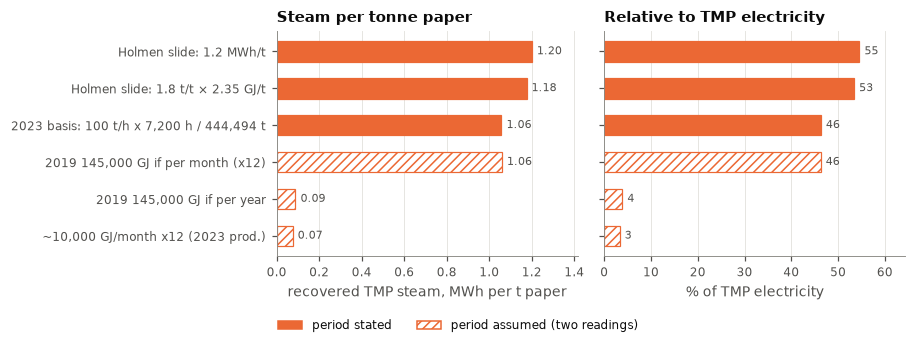

**Takeaway.** The Holmen slide (undated) gives 1.20 MWh/t (55 % of TMP electricity, its own implied ratio 1.2/2.20); the 2023 basis (100 t/h) gives 1.06 MWh/t, 46 % of TMP electricity, i.e. about 12 % less per tonne, consistent with higher electric-boiler use in section 2 (production bases and enthalpy differ, so this is indicative). The 2019 145,000 GJ is only consistent with the other values if read as per month; read as per year it is ~10x too small. Holmen (2025) says recovery covers 70-90 % of the steam need. Holmen's own account (`narr_boiler_driver_2023`): “Det är framför allt ångåtervinning från TMP samt återvinning av energi för varmvattenproduktion som har en förbättringspotential. Brister i dessa två områden bidrar till hög elförbrukning i våra elpannor.” ('steam recovery from TMP and energy recovery for hot-water production have most room for improvement; shortfalls in these two contribute to high electricity use in our electric boilers').

In [4]:
kwh = H/3.6  # MWh per t steam
tmp_el_23 = tot23*1e3*v('el_split_tmp_2025')/100/P23       # MWh/t paper, 2025 share on 2023
tmp_el_19 = tot19*1e3*v('el_split_tmp_2019')/100/p19
pp = v('pptx_steam_recovered'); pp_t = v('pptx_steam_mass')
rows = [
 ('Holmen slide: 1.2 MWh/t', pp, v('pptx_tmp_in'), False),
 ('Holmen slide: 1.8 t/t × 2.35 GJ/t', pp_t*kwh, v('pptx_tmp_in'), False),
 (f"2023 basis: {MODEL['tmp_steam_th']:.0f} t/h x {HRS:,} h / {P23:,.0f} t", MODEL['tmp_steam_th']*HRS/P23*kwh, tmp_el_23, False),
 ('2019 145,000 GJ if per month (x12)', v('steam_tmp_net_2019')*12/3.6e3/(p19/1e3), tmp_el_19, True),
 ('2019 145,000 GJ if per year', v('steam_tmp_net_2019')/3.6e3/(p19/1e3), tmp_el_19, True),
 ('~10,000 GJ/month x12 (2023 prod.)', v('steam_tmp_10000GJ_month_unknown')*12/3.6e3/(P23/1e3), tmp_el_23, True)]
st = pd.DataFrame(rows, columns=['basis', 'steam_MWh_per_t_paper', 'tmp_el_MWh_per_t_paper', 'period_assumed'])
st['steam_t_per_t_paper'] = st.steam_MWh_per_t_paper/kwh
st['steam_share_of_tmp_el_pct'] = st.steam_MWh_per_t_paper/st.tmp_el_MWh_per_t_paper*100
tab(st.round(4), 'tmp_steam'); display(st.round(3))
fig, ax = plt.subplots(1, 2, figsize=(8.4, 2.9), sharey=True)
y = np.arange(len(st))[::-1]
for a, col, lab, fmt in zip(ax, ['steam_MWh_per_t_paper', 'steam_share_of_tmp_el_pct'], ['recovered TMP steam, MWh per t paper', '% of TMP electricity'], ['{:.2f}', '{:.0f}']):
    for yy, val, h in zip(y, st[col], st.period_assumed):
        a.barh(yy, val, height=.55, color='white' if h else C['steam'], edgecolor=C['steam'], hatch='////' if h else None, linewidth=.8)
        a.text(val + st[col].max()*.02, yy, fmt.format(val), va='center', fontsize=7, color=INK2)
    a.set_xlabel(lab); a.set_xlim(0, st[col].max()*1.18); a.grid(axis='y', visible=False)
ax[0].set_yticks(y); ax[0].set_yticklabels(st.basis)
ax[0].set_title('Steam per tonne paper'); ax[1].set_title('Relative to TMP electricity')
from matplotlib.patches import Patch
fig.legend([Patch(fc=C['steam'], ec=C['steam']), Patch(fc='white', ec=C['steam'], hatch='////')], ['period stated', 'period assumed (two readings)'], ncol=2, loc='upper center', bbox_to_anchor=(.5, 0.02), frameon=False)
fig.tight_layout(); plotstyle.save(fig, 'eda_tmp_steam'); plt.show()
lo, hi = rng('steam_recovery_rate_2025')
say(f"**Takeaway.** The Holmen slide (undated) gives {st.steam_MWh_per_t_paper[0]:.2f} MWh/t ({st.steam_share_of_tmp_el_pct[0]:.0f} % of TMP electricity, its own implied ratio 1.2/2.20); the 2023 basis (100 t/h) gives {st.steam_MWh_per_t_paper[2]:.2f} MWh/t, {st.steam_share_of_tmp_el_pct[2]:.0f} % of TMP electricity, i.e. about {100*(1-st.steam_MWh_per_t_paper[2]/st.steam_MWh_per_t_paper[0]):.0f} % less per tonne, consistent with higher electric-boiler use in section 2 (production bases and enthalpy differ, so this is indicative). "
    f"The 2019 145,000 GJ is only consistent with the other values if read as per month; read as per year it is ~10x too small. Holmen (2025) says recovery covers {lo:.0f}-{hi:.0f} % of the steam need. Holmen's own account (`narr_boiler_driver_2023`): {nq('narr_boiler_driver_2023')} ('steam recovery from TMP and energy recovery for hot-water production have most room for improvement; shortfalls in these two contribute to high electricity use in our electric boilers').")

## 4. Water and heat carriers
Left: the 2023 water figures in the Miljörapport (Tabell 12 and text) beside Holmen's rough 2024 balance (2025 answer image). Right: effluent flow (Tabell 6) and district heat delivered, 2019 vs 2023 (2019 given as 16,000 GJ, converted to GWh).

**Supports report §5.1 (exit table):** the wastewater, cooling-water and district-heat exit quantities used in the model are consistent with the reported 2023 figures.

*Caption:* Water volumes in 2023 (Miljörapport) and in Holmen's rough 2024 balance, effluent flow 2019-2023 and district heat delivered in 2019 and 2023. The 2024 balance includes 4 Mm³ of cooling and non-affected water.

,item,Mm3_per_yr,basis
0,Raw water intake,11.047000,2023 Miljoerapport
1,Process water,6.666000,2023 Miljoerapport
2,Effluent to Edeboviken,7.288861,2023 Miljoerapport
3,Fresh water in,11.800000,2024 rough balance (Holmen 2025)
4,WWTP effluent,7.000000,2024 rough balance (Holmen 2025)
5,Cooling / non-affected,4.000000,2024 rough balance (Holmen 2025)
6,Evaporation,0.800000,2024 rough balance (Holmen 2025)
7,Sludge,0.050000,2024 rough balance (Holmen 2025)


,year,dh_GWh
0,2019,4.444444
1,2023,11.877000


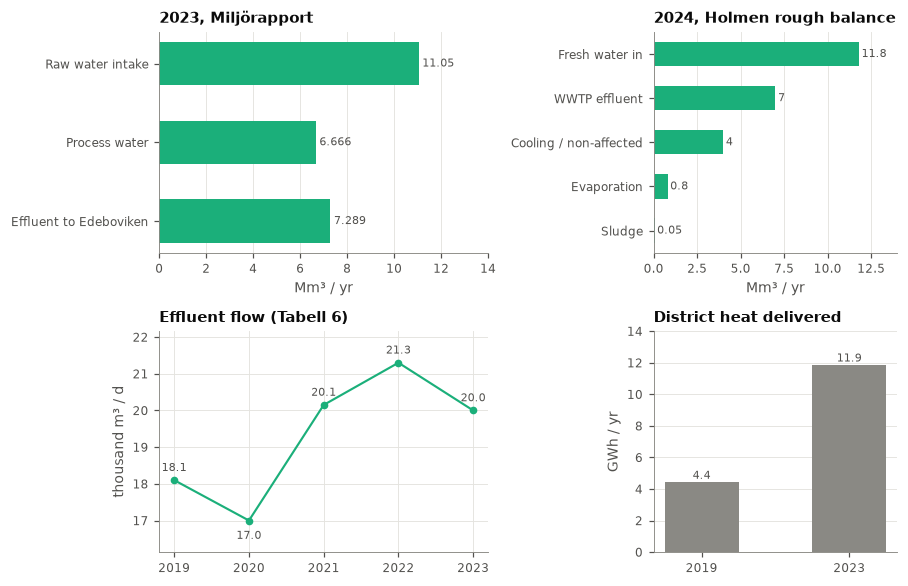

**Takeaway.** Effluent volume is stable across sources (2023 total 7.29 Mm³ vs 2024 balance 7 Mm³), but the 2024 balance's 11.8 Mm³ inflow is not directly comparable with the 2023 raw-water intake of 11.05 Mm³ (different year, includes chemicals and wood) and it carries a further 4 Mm³ of cooling water that has no 2023 counterpart. Daily effluent flow varies 17.0-21.3 thousand m³/d over five years, 2023 near the middle. District heat rose from 4.4 GWh (2019, quoted as approx. 16,000 GJ) to 11.9 GWh (2023), a factor 2.7; the 2019 figure is approximate and a different unit, so treat the factor with care.

In [5]:
w23 = pd.DataFrame({'item': ['Raw water intake', 'Process water', 'Effluent to Edeboviken'],
    'Mm3_per_yr': [v('water_raw_total_2023')/1e6, v('water_process_2023')/1e6, v('effluent_total_2023')/1e6], 'basis': '2023 Miljoerapport'})
w24 = pd.DataFrame({'item': ['Fresh water in', 'WWTP effluent', 'Cooling / non-affected', 'Evaporation', 'Sludge'],
    'Mm3_per_yr': [v(k) for k in ['img_wb_in', 'img_wb_wwtp', 'img_wb_cooling', 'img_wb_evap', 'img_wb_sludge']], 'basis': '2024 rough balance (Holmen 2025)'})
wt = pd.concat([w23, w24], ignore_index=True); wt.rename(columns={'Mm3_per_yr': 'volume_Mm³_per_yr'}).to_csv(TAB / 'eda_water_balance.csv', index=False); display(wt)
ef = pd.DataFrame({'year': YRS, 'effluent_m3_per_d': [v(f'eff_flow_{y}_t6') for y in YRS]})
dh = pd.DataFrame({'year': [2019, 2023], 'dh_GWh': [v('dh_2019')/3.6e3, v('dh_export_2023')/1e3]})
tab(ef, 'effluent_flow'); tab(dh, 'district_heat'); display(dh)
fig, ax = plt.subplots(2, 2, figsize=(8.4, 5.4), gridspec_kw={'width_ratios': [1.35, 1]})
for a, d, t in zip(ax[0], [w23, w24], ['2023, Miljörapport', '2024, Holmen rough balance']):
    yy = np.arange(len(d))[::-1]
    a.barh(yy, d.Mm3_per_yr, height=.55, color=C['water'])
    for y_, val in zip(yy, d.Mm3_per_yr): a.text(val + .15, y_, f"{val:.4g}", va='center', fontsize=7.5, color=INK2)
    a.set_yticks(yy); a.set_yticklabels(d.item); a.set_title(t); a.set_xlabel('Mm³ / yr'); a.grid(axis='y', visible=False); a.set_xlim(0, 14)
a = ax[1, 0]; a.plot(ef.year, ef.effluent_m3_per_d/1e3, '-o', color=C['water'], ms=4, lw=1.4)
for y_, val in zip(ef.year, ef.effluent_m3_per_d/1e3): a.annotate(f"{val:.1f}", (y_, val), xytext=(0, -12 if y_ == 2020 else 6), textcoords='offset points', ha='center', fontsize=7.5, color=INK2)
a.set_xticks(YRS); a.set_title('Effluent flow (Tabell 6)'); a.set_ylabel('thousand m³ / d'); a.margins(y=.2)
a = ax[1, 1]; a.bar([str(y) for y in dh.year], dh.dh_GWh, width=.5, color=C['waste heat'])
for i, val in enumerate(dh.dh_GWh): a.text(i, val + .2, f"{val:.1f}", ha='center', fontsize=7.5, color=INK2)
a.set_title('District heat delivered'); a.set_ylabel('GWh / yr'); a.set_ylim(0, 14); a.grid(axis='x', visible=False)
fig.tight_layout(); plotstyle.save(fig, 'eda_water_heat'); plt.show()
say(f"**Takeaway.** Effluent volume is stable across sources (2023 total {w23.Mm3_per_yr[2]:.2f} Mm³ vs 2024 balance {w24.Mm3_per_yr[1]:.0f} Mm³), but the 2024 balance's 11.8 Mm³ inflow is not directly comparable with the 2023 raw-water intake of {w23.Mm3_per_yr[0]:.2f} Mm³ (different year, includes chemicals and wood) and it carries a further 4 Mm³ of cooling water that has no 2023 counterpart. Daily effluent flow varies {ef.effluent_m3_per_d.min()/1e3:.1f}-{ef.effluent_m3_per_d.max()/1e3:.1f} thousand m³/d over five years, 2023 near the middle. District heat rose from {dh.dh_GWh[0]:.1f} GWh (2019, quoted as approx. 16,000 GJ) to {dh.dh_GWh[1]:.1f} GWh (2023), a factor {dh.dh_GWh[1]/dh.dh_GWh[0]:.1f}; the 2019 figure is approximate and a different unit, so treat the factor with care.")

## 5. Reconciliation of model inputs against all source values
One row per source value. *Common value* is converted only where the period/basis is stated; unstated-period values carry both readings in the flag text. Steam is converted with 2.35 GJ/t, and t/h to annual figures with 7,200 h (model value). Written to `reports/tables/eda_reconciliation.csv`.

**Supports report §4.1 and Table 6.2 (replaces Appendix A):** every model input is traced to its source values, with conflicts flagged.

*Caption:* Source values for each model input, converted to a common unit where the period is stated, with conflicts flagged and the value used in the model.

In [6]:
R = []
def add(inp, model, sid, text, cv=None, cu='', flag='', year=None, source=None):
    if sid in src.index:
        year = year or f"{src.loc[sid,'data_year']} (doc {src.loc[sid,'source_year']})"; source = source or src.loc[sid, 'source_file'].split('.')[0]
    R.append(dict(model_input=inp, source_id=sid, source=source, year=year, source_value=text,
                  common_value=None if cv is None else round(cv, 3), common_unit=cu, flag=flag, value_used_in_model=model))
def rg(i, u=''): lo, hi = rng(i); return f"{lo:g}-{hi:g} {u}".strip()
mE = f"{MODEL['E_GWh']} GWh/yr"
for y in (2019, 2023): add('Total electricity', mE, f'el_total_{y}_t13', f"{v(f'el_total_{y}_t13'):g} GWh", v(f'el_total_{y}_t13'), 'GWh/yr')
add('Total electricity', mE, 'el_total_2025', f"{v('el_total_2025'):g} TWh/yr", v('el_total_2025')*1e3, 'GWh/yr', 'Year not stated; rounded')
add('Total electricity', mE, 'pptx_total_gwh', f"{v('pptx_total_gwh'):g} GWh/yr total energy", v('pptx_total_gwh'), 'GWh/yr', 'All energy, 565 kt basis; similar to sum of Holmen slide (undated) electricity boxes')
aug_sum = tmp3 + tmp12 + pm11 + pm12
add('Total electricity', mE, 'el_tmp3_aug2019', f"Aug 2019 sum {aug_sum:,.0f} MWh/month", aug_sum*12/1e3, 'GWh/yr (x12)', f"CONFLICT: x12 is below 2019 annual {v('el_total_2019_t13'):g} GWh (single month, no boilers/other)")
add('Electricity shares TMP/PM/EB/other %', '70/15/10/5', 'el_split_tmp_2019', f"{s19[0]:g}/{s19[1]:g}/{s19[2]:g}", s19[2], '% EB', 'Average of last 3 years (~2017-19); EB 6 % vs 10 % in 2025 answer')
add('Electricity shares TMP/PM/EB/other %', '70/15/10/5', 'el_split_tmp_2025', f"{s25[0]:g}/{s25[1]:g}/{s25[2]:g}/{s25[3]:g} (remainder)", s25[2], '% EB', 'Stated shares sum to 95 %; 5 % is remainder, not a source value')
pt = v('pptx_total_spec')
add('Electricity shares TMP/PM/EB/other %', '70/15/10/5', 'pptx_ep', f"derived {v('pptx_tmp_in')/pt*100:.0f}/{v('pptx_pm')/pt*100:.0f}/{v('pptx_ep')/pt*100:.0f}", v('pptx_ep')/pt*100, '% EB', 'Derived from MWh/t boxes / 3.02; EB ~4 %. CONFLICT with 6 and 10 %')
add('Electricity shares TMP/PM/EB/other %', '70/15/10/5', 'el_tmp3_aug2019', f"Aug 2019 line values {aug_sh[0]:.0f}/{aug_sh[1]:.0f}/n.a.", None, '', 'Single month; no boiler value')
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'tmp_steam_recycled_2025', "~100 t/h", 100, 't/h', f"= {100*HRS*H/3.6e3:.0f} GWh/yr steam at {HRS} h")
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'pptx_steam_mass', f"{pp_t:g} t/F-ton ({pp:g} MWh/F-ton)", pp_t*v('pptx_total_prod')*1e3/HRS, 't/h (565 kt, 7,200 h)', f"= {pp_t*P23/HRS:.0f} t/h at 2023 production. Higher than 100 t/h; year unknown")
t3 = rng('steam_tmp3_use_aq')
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'steam_tmp_net_2019', "145,000 GJ, period not stated", None, '', f"CONFLICT: per month = {v('steam_tmp_net_2019')/H/720:.0f} t/h; per year = {v('steam_tmp_net_2019')/H/HRS:.0f} t/h (at 720 h/month, {HRS} h/yr)")
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'steam_tmp_10000GJ_month_unknown', "~10,000 GJ/month", v('steam_tmp_10000GJ_month_unknown')/H/720, 't/h (720 h)', 'CONFLICT: ~17x below 100 t/h; "steam production", year "recently"')
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'steam_tmp3_use_aq', rg('steam_tmp3_use_aq', 'GJ/month'), None, '', f"TMP3 only: {t3[0]/H/720:.1f}-{t3[1]/H/720:.1f} t/h (720 h); range of 10x")
add('TMP recovered steam', f"{MODEL['tmp_steam_th']} t/h", 'steam_recovery_rate_2025', rg('steam_recovery_rate_2025', '% of need'), None, '', 'Share of steam need, not an absolute flow')
add('PM drying steam', f"{MODEL['pm_steam_th']} t/h ({MODEL['pm_steam_rng'][0]}-{MODEL['pm_steam_rng'][1]})", 'pm_steam_2025', rg('pm_steam_2025', 't/h'), None, 't/h', 'Range; model point value sits mid-range')
add('PM drying steam', f"{MODEL['pm_steam_th']} t/h ({MODEL['pm_steam_rng'][0]}-{MODEL['pm_steam_rng'][1]})", 'steam_pm_2019', "155,000 GJ, period not stated", None, '', f"CONFLICT: per month = {v('steam_pm_2019')/H/720:.0f} t/h (fits 2025 range); per year = {v('steam_pm_2019')/H/HRS:.0f} t/h")
add('Boiler steam yield / efficiency', f"eff {MODEL['boiler_eff']} (yield {MODEL['boiler_yield']} t/MWh)", 'steam_per_MW_2025', f"{v('steam_per_MW_2025'):g} t steam per MW (per h)", v('steam_per_MW_2025'), 't/MWh', f"Implied efficiency at {H} GJ/t: {v('steam_per_MW_2025')*H/3.6:.2f}. Efficiency itself not in register")
add('Steam pressure (bar)', f"{MODEL['p_bar_abs']} bar abs", 'steam_pressure_2019', f"{v('steam_pressure_2019'):g} bar", v('steam_pressure_2019'), 'bar (g/abs not stated)', 'Gauge/absolute not stated; 138 degC saturation matches ~3.4 bar abs, i.e. 2.4 bar gauge')
add('Steam pressure (bar)', f"{MODEL['p_bar_abs']} bar abs", 'steam_pressure_pm_2019', f"{v('steam_pressure_pm_2019'):g} bar", v('steam_pressure_pm_2019'), 'bar (g/abs not stated)', '2.4 vs 2.5 bar; 3.4 bar abs is not in the register')
add('Steam temperature', f"{MODEL['T_steam']} degC", 'steam_temp_2p4bar_2019', f"{v('steam_temp_2p4bar_2019'):g} degC at 2.4 bar", v('steam_temp_2p4bar_2019'), 'degC')
add('Condensate temperature', f"{MODEL['T_cond']} degC", 'condensate_temp_pm_2019', f"approx {v('condensate_temp_pm_2019'):g} degC from PM", v('condensate_temp_pm_2019'), 'degC', 'Agrees with model')
add('Effluent temperature', f"{MODEL['T_eff']} degC", 'effluent_dT_sea_2019', f"{v('effluent_dT_sea_2019'):g} (asked as difference to sea)", None, 'degC or K', 'AMBIGUOUS: delta T vs absolute; model 35 degC is not in the register')
add('Effluent temperature', f"{MODEL['T_eff']} degC", 'effluent_dT_sea_shutdown_2019', f"{v('effluent_dT_sea_shutdown_2019'):g} (long shutdowns)", None, 'degC or K', 'Same ambiguity')
add('Effluent temperature', f"{MODEL['T_eff']} degC", 'pm_wastewater_T_2019', f"{v('pm_wastewater_T_2019'):g} degC (PM wastewater)", v('pm_wastewater_T_2019'), 'degC', 'Before mixing/WWTP; warmer than model effluent')
MEff = f"{MODEL['eff_Mm3']} Mm³/yr"
add('Effluent volume', MEff, 'effluent_total_2023', f"{v('effluent_total_2023'):,.0f} m³/yr", v('effluent_total_2023')/1e6, 'Mm³/yr')
add('Effluent volume', MEff, 'eff_flow_2023_t6', f"{v('eff_flow_2023_t6'):,.0f} m³/d", v('eff_flow_2023_t6')*365/1e6, 'Mm³/yr (x365)', 'Rounded daily value')
add('Effluent volume', MEff, 'effluent_wwtp_daily_2023', f"{v('effluent_wwtp_daily_2023'):,.0f} m³/d (WWTP outlet)", v('effluent_wwtp_daily_2023')*365/1e6, 'Mm³/yr (x365)', 'Outlet of chemical treatment only; lower than total')
add('Effluent volume', MEff, 'wwtp_out_2024', "13.5 m³/min", v('wwtp_out_2024')*525.6e3/1e6, 'Mm³/yr', 'Year not stated (~2024)')
add('Effluent volume', MEff, 'img_wb_wwtp', "7 Mm³/yr", v('img_wb_wwtp'), 'Mm³/yr', '2024 rough balance; excludes 4 Mm³ cooling/non-affected water')
add('Effluent volume', MEff, 'effluent_flow_wwtp_2019', rg('effluent_flow_wwtp_2019', 'm³/min'), None, 'Mm³/yr', f"= {rng('effluent_flow_wwtp_2019')[0]*525.6e3/1e6:.2f}-{rng('effluent_flow_wwtp_2019')[1]*525.6e3/1e6:.2f} Mm³/yr; 2019 lower")
d11, d12 = v('pm11_days_2023'), v('pm12_days_2023'); q11, q12 = v('pm11_prod_2023'), v('pm12_prod_2023')
hw = (q11*d11 + q12*d12)/(q11+q12)*24
MH = f"{HRS:,} h"
add('Operating hours', MH, 'pm11_days_2023', f"{d11:g} d", d11*24, 'h/yr')
add('Operating hours', MH, 'pm12_days_2023', f"{d12:g} d", d12*24, 'h/yr')
add('Operating hours', MH, 'pm11_prod_2023', 'production-weighted PM11/PM12', hw, 'h/yr', 'Derived (weights = PM production, Tabell 4); model rounds up by ~26 h', source='derived')
add('Operating hours', MH, 'wwtp_days_2023', f"{v('wwtp_days_2023'):g} d", v('wwtp_days_2023')*24, 'h/yr', 'WWTP runs all year; not the paper operating time')
add('TMP specific electricity', '2,406 kWh/t', 'tmp_el_spec_2025', rg('tmp_el_spec_2025', 'kWh/t'), None, 'kWh/t', 'Refining only')
add('TMP specific electricity', '2,406 kWh/t', 'tmp_refining_el_2025', f"{v('tmp_refining_el_2025'):g} + {v('tmp_aux_el_2025'):g} aux kWh/t", v('tmp_refining_el_2025')+v('tmp_aux_el_2025'), 'kWh/t', 'Holmen upper end plus auxiliary: 2,150; model is ~12 % above')
tmp_t = v('prod_tmp_2023')
add('TMP specific electricity', '2,406 kWh/t', 'el_split_tmp_2025', '70 % x 1450 GWh / TMP 2023 t', tot23*1e6*v('el_split_tmp_2025')/100/tmp_t, 'kWh/t TMP', 'Derived: reproduces the model value; above Holmen range (1,650-2,150 incl. aux)', source='derived')
add('TMP specific electricity', '2,406 kWh/t', 'pptx_tmp_in', f"{v('pptx_tmp_in'):g} MWh/t paper", v('pptx_tmp_in')*1e3*P23/tmp_t, 'kWh/t TMP (x paper/TMP, 2023)', 'Derived with 2023 paper/TMP ratio; Holmen slide (undated) year unknown', source='derived')
add('TMP specific electricity', '2,406 kWh/t', 'narr_l12_quality_2023', 'qualitative: ' + nq('narr_l12_quality_2023') + ' (extra refining electricity to hold pulp quality, mainly L12, in 2023)', None, '', 'Candidate explanation for 2,406 vs 1,650-2,150 kWh/t; not quantified')
MDH = f"{MODEL['dh_GWh']} GWh"
add('District heat', MDH, 'dh_export_2023', '11,877 MWh', v('dh_export_2023')/1e3, 'GWh/yr')
add('District heat', MDH, 'dh_2019', '~16,000 GJ', v('dh_2019')/3.6e3, 'GWh/yr', 'CONFLICT: 2019 is 2.7x lower; approximate')
rec = pd.DataFrame(R); rec.to_csv(TAB / 'eda_reconciliation.csv', index=False)
pd.set_option('display.max_colwidth', 120, 'display.max_rows', 100, 'display.width', 250)
display(rec.style.hide(axis='index').set_properties(**{'text-align': 'left', 'font-size': '8pt'}))
nconf = rec.flag.str.contains('CONFLICT|AMBIGUOUS').sum()
say(f"**Takeaway.** {len(rec)} source values across {rec.model_input.nunique()} model inputs; {nconf} are flagged CONFLICT or AMBIGUOUS. Where a period is stated the values agree with the model within the stated ranges (electricity 1450-1500 GWh, effluent 6.6-7.3 Mm³, hours 6,800-7,500 h). The weakest inputs are steam flows quoted in GJ with no period (read as per month they match 100 and 95 t/h, as per year they are ~10x too small), the effluent temperature (35 degC is not in the register), and the 5 % unassigned electricity share. Not in the register and therefore model-only: boiler efficiency 0.98, 3.4 bar abs, 35 degC, the 5 % remainder, 7,200 h.")

model_input,source_id,source,year,source_value,common_value,common_unit,flag,value_used_in_model
Total electricity,el_total_2019_t13,Miljörapport 2023 Hallsta-1,2019 (doc 2023),1451 GWh,1451.000000,GWh/yr,,1450 GWh/yr
Total electricity,el_total_2023_t13,Miljörapport 2023 Hallsta-1,2023 (doc 2023),1450 GWh,1450.000000,GWh/yr,,1450 GWh/yr
Total electricity,el_total_2025,Student questions to Holmen 2025 (ANRA 251021),2025 (year not stated) (doc 2025),1.5 TWh/yr,1500.000000,GWh/yr,Year not stated; rounded,1450 GWh/yr
Total electricity,pptx_total_gwh,Viktiga Energiflöden-1 (1)-1,unknown (doc unknown),1707 GWh/yr total energy,1707.000000,GWh/yr,"All energy, 565 kt basis; similar to sum of Holmen slide (undated) electricity boxes",1450 GWh/yr
Total electricity,el_tmp3_aug2019,Compiled questions to Holmen 2019,2019-08 (doc 2019),"Aug 2019 sum 106,000 MWh/month",1272.000000,GWh/yr (x12),"CONFLICT: x12 is below 2019 annual 1451 GWh (single month, no boilers/other)",1450 GWh/yr
Electricity shares TMP/PM/EB/other %,el_split_tmp_2019,Questions for the study visit (Answers Hallsta),avg last 3 yrs (~2017-19) (doc 2019/2020),72/22/6,6.000000,% EB,Average of last 3 years (~2017-19); EB 6 % vs 10 % in 2025 answer,70/15/10/5
Electricity shares TMP/PM/EB/other %,el_split_tmp_2025,Student questions to Holmen 2025 (ANRA 251021),2025 (doc 2025),70/15/10/5 (remainder),10.000000,% EB,"Stated shares sum to 95 %; 5 % is remainder, not a source value",70/15/10/5
Electricity shares TMP/PM/EB/other %,pptx_ep,Viktiga Energiflöden-1 (1)-1,unknown (doc unknown),derived 73/23/4,3.974000,% EB,Derived from MWh/t boxes / 3.02; EB ~4 %. CONFLICT with 6 and 10 %,70/15/10/5
Electricity shares TMP/PM/EB/other %,el_tmp3_aug2019,Compiled questions to Holmen 2019,2019-08 (doc 2019),Aug 2019 line values 79/21/n.a.,nan,,Single month; no boiler value,70/15/10/5
TMP recovered steam,tmp_steam_recycled_2025,Student questions to Holmen 2025 (ANRA 251021),2025 (doc 2025),~100 t/h,100.000000,t/h,= 470 GWh/yr steam at 7200 h,100 t/h


**Takeaway.** 42 source values across 13 model inputs; 7 are flagged CONFLICT or AMBIGUOUS. Where a period is stated the values agree with the model within the stated ranges (electricity 1450-1500 GWh, effluent 6.6-7.3 Mm³, hours 6,800-7,500 h). The weakest inputs are steam flows quoted in GJ with no period (read as per month they match 100 and 95 t/h, as per year they are ~10x too small), the effluent temperature (35 degC is not in the register), and the 5 % unassigned electricity share. Not in the register and therefore model-only: boiler efficiency 0.98, 3.4 bar abs, 35 degC, the 5 % remainder, 7,200 h.

In [7]:
pd.DataFrame([
 ('eda_context.png', '3.4, 5.2', '2023 is a usable reference year; stops (price, market, MBBR) raise SEC but Holmen also reports higher SEC in full-run periods (narr_price_stops_2023, narr_market_stops_2023, narr_full_run_sec_2023).', 'Electricity, derived paper production and specific energy consumption at Hallsta, 2019-2023 (Miljörapport Tabell 13). 2023 (shaded) is the second-lowest output year and has the highest SEC; Miljörapport §1.2.1 attributes this to price- and market-driven stops and the MBBR outage, and also to a higher SEC in full-run periods.'),
 ('eda_electricity_split.png', '4.1, 6.2, 7', 'Share ranges (TMP 65-75 %, PM 12-22 %, EB 5-12 %) span the data vintages; boiler intensity has risen.', 'Electricity split by process in four data vintages, as MWh per tonne of paper (left) and share of total (right). The Aug 2019 line values are one month and give shares only; electric-boiler intensity rises from 0.12 to 0.33 MWh/t.'),
 ('eda_tmp_steam.png', '5.1, 7 (Measure 1)', 'Recovered TMP steam per tonne is lower than the older Holmen slide value; Holmen names TMP and hot-water recovery shortfalls as drivers of boiler use (narr_boiler_driver_2023); model TMP share vs Holmen 70-90 %.', 'Recovered TMP steam per tonne of paper (left) and relative to TMP electricity (right) for each source basis. Hatched bars use an assumed period for values with none stated (2.35 GJ/t steam). The ~10,000 GJ/month and 145,000 GJ per year readings are physically inconsistent with 100 t/h, so they cannot refer to total TMP recovered steam.'),
 ('eda_water_heat.png', '5.1 (exit table)', 'Wastewater, cooling-water and district-heat exits in the model match reported 2023 figures.', "Water volumes in 2023 (Miljörapport) and in Holmen's rough 2024 balance, effluent flow 2019-2023 and district heat delivered in 2019 and 2023. The 2024 balance includes 4 Mm³ of cooling and non-affected water."),
 ('eda_reconciliation.csv', '4.1, Table 6.2, Appendix A', 'Every model input traced to source values; conflicts flagged.', 'Source values for each model input (TMP specific electricity: narr_l12_quality_2023 as candidate explanation), converted to a common unit where the period is stated, with conflicts flagged and the value used in the model.'),
], columns=['figure_or_table', 'report_section', 'claim_supported', 'caption']).to_csv(TAB / 'eda_report_map.csv', index=False)